In [3]:
import sys
sys.path.append('../')

import numpy as np
import matplotlib.pyplot as plt


import config

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [62]:
def F(t, y):
    return y**2

def RK4(f, ti, tf, N, X0, M=None):
    """ Función que entrega la aproximación numérica de Runge Kutta 4 
    para la solución al problema X' = f(t,X).

    f: Función f(t,X,args) que es función de lado derecho de la ecuación
    ti: t inicial
    tf: t final
    h: Paso h del método
    X0: Condición inicial
    args: Argumentos a entregar a la función f

    Regresa (t,X) donde t es el intervalo [ti,tf] equiespaciado y X
    la aproximación a la solución mediante método de Runge Kutta de orden 4.
    """
    # Cardinal del equiespaciado del método
    #N = Nt #int((abs(tf-ti))/h)

    # Arreglo de t
    t = np.linspace(ti, tf, N) #np.arange(ti, tf, h)
    #N = len(t)
    h = np.abs(t[1] - t[0])
    Nx = len(X0)

    # Arreglo para la solución
    X = np.zeros((N, Nx))

    # Condición inicial
    X[0] = X0

    # Método de Runge Kutta 4
    for i in range(N-1):
        g1 = f(t[i]      , X[i]       )
        g2 = f(t[i] + h/2, X[i]+h/2*g1)
        g3 = f(t[i] + h/2, X[i]+h/2*g2)
        g4 = f(t[i] + h  , X[i]+h*g3  )
        X[i+1] = X[i] + h/6*(g1 + 2*g2 + 2*g3 + g4)
        if M is not None:
            if np.abs(X[i+1]) > M:
                break

    return (t,X.T)

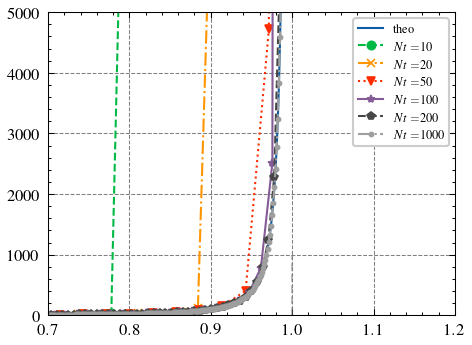

[1.2444444444444445,
 1.1052631578947367,
 1.0571428571428572,
 1.018181818181818,
 1.0130653266331657,
 1.002002002002002]

In [71]:
def y_theo(t):
    return 1/(1-t)

#dts = np.array([0.1, 0.05, 0.02, 0.01, 0.005, 0.001]) #[10**(-j) for j in range(1, 7)]
Nts = np.array([10, 20, 50, 100, 200, 1000])
#dts = 1/Nts

ti = 0
tf = 1.4

ts_bl = []
sols = []
M = 1e20

t_theo = np.linspace(0, 1, int(1e6))[:-1]
dt_theo = t_theo[1] - t_theo[0]

plt.plot(t_theo, np.gradient(y_theo(t_theo), dt_theo), label="theo")
plt.vlines(1, 0, 1e3, ls="--", color="gray", alpha = .5)

for Nt in Nts:
    t, y_sol = RK4(F, ti, tf, Nt, [1], M=M)
    dt = np.abs(t[1] - t[0])
    cond = y_sol[0]>0
    ts_bl += [t[cond][-1]]
    sols += [y_sol[0]]
    y_sol_p = np.gradient(y_sol[0][cond], dt)

    plt.plot(t[cond], y_sol_p, label=r"$Nt=${}".format(Nt))
    #plt.plot(t[:-1], y_theo_p, label="Theo")

plt.ylim(0, 5e3)
#plt.yscale("log")
plt.xlim(0.7, 1.2)
plt.legend(fontsize=6)
plt.show()
ts_bl

In [76]:
def t_bl_guess(Nt, M, t_guess):
    t_dt, y_dt = RK4(F, 0, t_guess, Nt, [1])
    t_dt_half, y_dt_half = RK4(F, 0, t_guess, int(Nt*2), [1])
    y_dt = y_dt[0]
    y_dt_half = y_dt_half[0]

    y_dt_half = y_dt_half[::2]
    rate = np.max(np.abs(y_dt_half/y_dt))
    
    return rate < M 

In [93]:
def bisection(t_g_1, t_g_2, Nt, M, tolerance=1e-8, max_iter=1000):
    j = 0
    while np.abs(t_g_2 - t_g_1) > tolerance and j < max_iter:

        m = (t_g_1 + t_g_2) / 2
        guess = t_bl_guess(Nt, M, m)
        print("t guess = ", m, ", guess ", guess)
        
        if guess:
            t_g_1 = m

        else:
            t_g_2 = m

        j += 1

    return (t_g_1 + t_g_2) / 2

t_guess_1 = 0.9
t_guess_2 = 1.2
M = 1.005
Nt = int(1e4) #np.sqrt(2)*1e-5

In [94]:
t_bl = bisection(t_guess_1, t_guess_2, Nt, M)

/var/folders/41/vskcwr5532bfb2q1wpk9q40h0000gn/T/ipykernel_8765/432781765.py:2: RuntimeWarning: overflow encountered in square
  return y**2
/var/folders/41/vskcwr5532bfb2q1wpk9q40h0000gn/T/ipykernel_8765/491077198.py:8: RuntimeWarning: invalid value encountered in divide
  rate = np.max(np.abs(y_dt_half/y_dt))


t guess =  1.05 , guess  False
t guess =  0.9750000000000001 , guess  True
t guess =  1.0125000000000002 , guess  False
t guess =  0.9937500000000001 , guess  True
t guess =  1.0031250000000003 , guess  False
t guess =  0.9984375000000002 , guess  True
t guess =  1.0007812500000002 , guess  False
t guess =  0.9996093750000001 , guess  True
t guess =  1.0001953125000003 , guess  False
t guess =  0.9999023437500002 , guess  True
t guess =  1.0000488281250002 , guess  False
t guess =  0.9999755859375001 , guess  True
t guess =  1.0000122070312503 , guess  True
t guess =  1.0000305175781252 , guess  False
t guess =  1.0000213623046879 , guess  False
t guess =  1.000016784667969 , guess  True
t guess =  1.0000190734863286 , guess  True
t guess =  1.0000202178955082 , guess  False
t guess =  1.0000196456909185 , guess  True
t guess =  1.0000199317932132 , guess  False
t guess =  1.0000197887420659 , guess  True
t guess =  1.0000198602676396 , guess  False
t guess =  1.0000198245048528 , gues

In [95]:
np.abs(1 - t_bl), t_bl

(1.9793212414187522e-05, 1.0000197932124142)